# ANN for Make Moons

I wanted to see if a small neural network could separate two curved groups of points. I used Scikit-learn to create the data, so no download is needed.


## Set up

I am using PyTorch on the CPU. The cells can be run in order in Jupyter Notebook.


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import make_moons
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device('cpu')
output_dir = Path('workshop_outputs/ann_make_moons')
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Using {torch.get_num_threads()} CPU threads')


Using 4 CPU threads


## Make the dataset

There are 1,500 points, with a little noise so the classes overlap in some places.


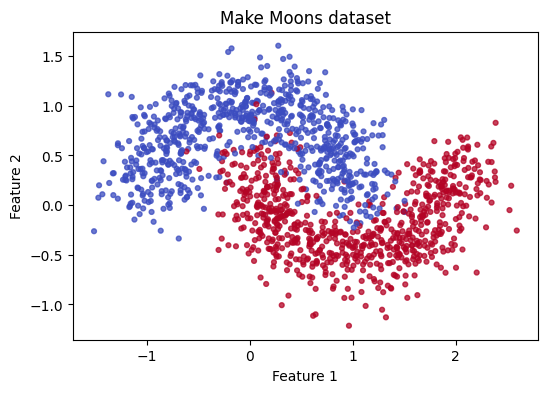

In [2]:
X, y = make_moons(n_samples=1500, noise=0.22, random_state=SEED)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=12, alpha=0.75)
plt.title('Make Moons dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()


## Prepare the samples

I split the data into training, validation and test sets. The scaler is fitted only on the training set.


In [3]:
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_val = scaler.transform(X_val).astype('float32')
X_test_scaled = scaler.transform(X_test).astype('float32')

train_data = TensorDataset(
    torch.from_numpy(X_train), torch.from_numpy(y_train.astype('float32')).unsqueeze(1)
)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_x = torch.from_numpy(X_val)
val_y = torch.from_numpy(y_val.astype('float32')).unsqueeze(1)
test_x = torch.from_numpy(X_test_scaled)
print(f'Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test_scaled)}')


Train: 1050 | Validation: 225 | Test: 225


## Build the network

Two hidden layers with ReLU activations should be enough to learn a nonlinear boundary.


In [4]:
class MoonANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.layers(x)

model = MoonANN().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(model)


MoonANN(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## Train

I use validation loss to decide which set of weights to keep.


In [5]:
epochs = 120
history = {'train_loss': [], 'val_loss': [], 'val_accuracy': []}
best_loss = float('inf')
best_weights = None

for epoch in range(1, epochs + 1):
    model.train()
    total_loss = 0
    for features, labels in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(features), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(features)

    model.eval()
    with torch.no_grad():
        scores = model(val_x)
        val_loss = loss_fn(scores, val_y).item()
        val_accuracy = ((scores >= 0).float() == val_y).float().mean().item()

    history['train_loss'].append(total_loss / len(train_data))
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_accuracy)

    if val_loss < best_loss:
        best_loss = val_loss
        best_weights = {name: weight.clone() for name, weight in model.state_dict().items()}

    if epoch == 1 or epoch % 20 == 0 or epoch == epochs:
        print(f'Epoch {epoch:3d}/{epochs} | Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.1%}')

model.load_state_dict(best_weights)
model.eval()


Epoch   1/120 | Val loss: 0.3850 | Val accuracy: 85.8%
Epoch  20/120 | Val loss: 0.1289 | Val accuracy: 94.7%
Epoch  40/120 | Val loss: 0.1305 | Val accuracy: 95.1%
Epoch  60/120 | Val loss: 0.1278 | Val accuracy: 95.6%
Epoch  80/120 | Val loss: 0.1358 | Val accuracy: 95.1%
Epoch 100/120 | Val loss: 0.1317 | Val accuracy: 95.6%
Epoch 120/120 | Val loss: 0.1280 | Val accuracy: 96.0%


MoonANN(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

## Check the results

The final accuracy is measured on points the model did not use during training.


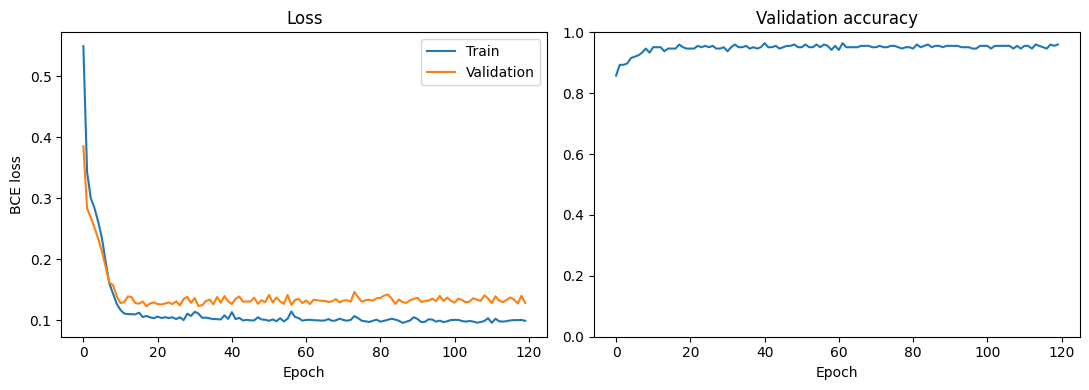

Test accuracy: 96.0%
              precision    recall  f1-score   support

      Moon 0       0.95      0.97      0.96       113
      Moon 1       0.97      0.95      0.96       112

    accuracy                           0.96       225
   macro avg       0.96      0.96      0.96       225
weighted avg       0.96      0.96      0.96       225



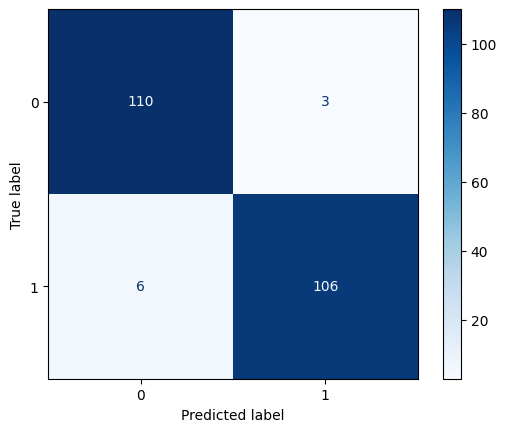

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set(title='Loss', xlabel='Epoch', ylabel='BCE loss')
axes[0].legend()
axes[1].plot(history['val_accuracy'])
axes[1].set(title='Validation accuracy', xlabel='Epoch', ylim=(0, 1))
plt.tight_layout()
plt.show()

with torch.no_grad():
    probabilities = torch.sigmoid(model(test_x)).numpy().ravel()
predictions = (probabilities >= 0.5).astype(int)
print(f'Test accuracy: {accuracy_score(y_test, predictions):.1%}')
print(classification_report(y_test, predictions, target_names=['Moon 0', 'Moon 1']))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Blues')
plt.show()


## Plot the decision boundary

This makes it easier to see where the model changes its prediction from one class to the other.


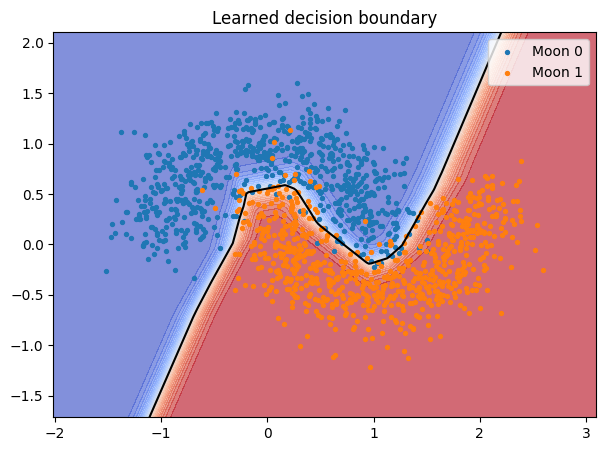

In [7]:
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 240),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 240)
)
grid = np.column_stack((xx.ravel(), yy.ravel()))
grid_tensor = torch.tensor(scaler.transform(grid), dtype=torch.float32)

with torch.no_grad():
    surface = torch.sigmoid(model(grid_tensor)).numpy().reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, surface, levels=25, cmap='coolwarm', alpha=0.65)
plt.contour(xx, yy, surface, levels=[0.5], colors='black')
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=8, label='Moon 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=8, label='Moon 1')
plt.title('Learned decision boundary')
plt.legend()
plt.show()


## Try a few points

I saved the model along with the scaling values, which are needed to predict new points.


In [8]:
def predict_points(points):
    values = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    scaled = torch.tensor(scaler.transform(values), dtype=torch.float32)
    with torch.no_grad():
        probabilities = torch.sigmoid(model(scaled)).numpy().ravel()
    return [(int(p >= 0.5), round(float(p), 3)) for p in probabilities]

examples = [[0.0, 0.5], [1.5, -0.2], [-0.8, 0.7]]
for point, result in zip(examples, predict_points(examples)):
    print(f'{point}: class {result[0]} (probability {result[1]})')

checkpoint = output_dir / 'moon_ann.pt'
torch.save({
    'model_state': model.state_dict(),
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist()
}, checkpoint)
print('Saved model:', checkpoint.resolve())


[0.0, 0.5]: class 1 (probability 0.654)
[1.5, -0.2]: class 1 (probability 0.993)
[-0.8, 0.7]: class 0 (probability 0.0)
Saved model: /kaggle/working/workshop_outputs/ann_make_moons/moon_ann.pt


## Try changing something

Increase `noise` to `0.35` and see how the boundary and accuracy change.
